# Registration-free vs. registration-based: comparison

Does the registration-free spherical representation lose (or gain) anything compared with
conventional template registration? The **same 1,691 subjects, the same partitions, the same
classifiers, training protocol, thresholds and statistics** were run on three representations:

| Representation | How it is built |
|---|---|
| **Spherical** (registration-free) | rays from each subject's own centre of mass to its own boundary; 36 × 72 × 48 tensor |
| **MNI affine** | ANTs affine (12 dof) registration to the MNI152 2009 2 mm brain template |
| **MNI SyN** | ANTs SyN (affine + deformable) registration to the same template |
| **Regional volumes** | Harvard-Oxford subcortical atlas warped to each subject (inverse SyN), volumes / brain volume |
| **Spherical of MNI SyN** | the same spherical transform applied to the SyN-registered brain (template mask, so centre and boundary are shared); CNN3D and Spherical Transformer (Section 2b) |

All three volumetric representations share the N4 bias-field correction and median/MAD
intensity normalization. Classifiers: CNN3D (identical architecture; circular azimuth padding
only for the spherical input), and SVM / XGBoost / cosine prototypes on a 50-component PCA.

**Statistics.** Thresholds chosen on validation (Youden); 95% percentile-bootstrap CIs over
2,000 paired test resamples; the **pre-specified** registration pairs (Section 2) form their own
Holm family. Sections 5–6 are **exploratory** (not pre-specified) and are labelled as such.

Figures are exported to `figures/` in the journal format of `results.ipynb`.

In [1]:
import os, sys, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

REPO        = Path(os.environ.get("ADNI_REPO", Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
RESULTS_DIR = Path(os.environ.get("ADNI_RESULTS", REPO / "results"))
REG_DIR     = Path(os.environ.get("ADNI_REGISTERED", REPO / "registered_cache"))
FIG_DIR     = Path(os.environ.get("ADNI_FIGURES", REPO / "figures"))
FIG_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(REPO))
from evaluate import bootstrap_indices, bootstrap_auc, _manual_auc, percentile_ci, holm   # repo's verified statistics

MM = 1 / 25.4
COL1, COL15, COL2 = 90 * MM, 140 * MM, 190 * MM
INK, INK_2, GRID = "#1a1a1a", "#555555", "#e2e2e2"
mpl.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 9, "axes.titlesize": 9, "axes.labelsize": 9, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.fontsize": 9, "legend.title_fontsize": 9, "axes.linewidth": 0.6,
    "xtick.major.width": 0.6, "ytick.major.width": 0.6, "xtick.major.size": 2.5, "ytick.major.size": 2.5,
    "axes.edgecolor": INK_2, "axes.labelcolor": INK, "text.color": INK, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.4,
    "lines.linewidth": 1.2, "legend.frameon": False, "figure.dpi": 150, "savefig.dpi": 600,
    "savefig.bbox": "tight", "savefig.pad_inches": 0.02, "pdf.fonttype": 42, "ps.fonttype": 42,
})

# One colour per representation (assigned once, never re-cycled); marker shape also encodes it.
REP_COLOR  = {"Spherical": "#2a78d6", "MNI affine": "#4a3aa7", "MNI SyN": "#008300", "Regional volumes": "#e34948",
              "Spherical of MNI SyN": "#eb6834"}
REP_MARKER = {"Spherical": "o", "MNI affine": "s", "MNI SyN": "D", "Regional volumes": "^", "Spherical of MNI SyN": "v"}
REPS = ["Spherical", "MNI affine", "MNI SyN"]
CLASSIFIERS = ["CNN3D", "SVM (RBF)", "XGBoost", "Cosine Similarity"]
ROI = "Regional volumes (MNI SyN atlas)"
PROTO = {"iso1.0": "≤1.0 mm voxels", "slice1.2": "1.2 mm slices"}

def config(clf, rep):
    if clf == "CNN3D":
        return "CNN3D (best epoch)" if rep == "Spherical" else f"CNN3D, {rep} (best epoch)"
    return clf if rep == "Spherical" else f"{clf}, {rep}"

def rep_of(c):
    if c == ROI: return "Regional volumes"
    if "spherical of MNI SyN" in c: return "Spherical of MNI SyN"
    for r in ("MNI SyN", "MNI affine"):
        if r in c: return r
    return "Spherical"

def label(c):
    if c == ROI: return "Regional volumes"
    clf = c.split(",")[0].split(" (")[0]
    return f"{clf} · {rep_of(c)}"

def panel(ax, letter, x=-0.02, y=1.02):
    ax.text(x, y, f"({letter})", transform=ax.transAxes, fontsize=10, fontweight="bold", ha="right", va="bottom")

CAPTIONS = {}
def save(fig, name, caption):
    fig.savefig(FIG_DIR / f"{name}.pdf")
    fig.savefig(FIG_DIR / f"{name}.png", dpi=600)
    fig.savefig(FIG_DIR / f"{name}.tif", dpi=600, pil_kwargs={"compression": "tiff_lzw"})
    CAPTIONS[name] = caption
    w, h = fig.get_size_inches() / MM
    display(Markdown(f"**{name}** ({w:.0f} × {h:.0f} mm): {caption}"))

def pfmt(p):
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"

summary  = pd.read_csv(RESULTS_DIR / "summary.csv").set_index("config")
per_seed = pd.read_csv(RESULTS_DIR / "metrics_per_seed.csv")
preds    = pd.read_csv(RESULTS_DIR / "predictions.csv")
regcomp  = pd.read_csv(RESULTS_DIR / "registration_comparison.csv")
subgroup = pd.read_csv(RESULTS_DIR / "subgroup_auc.csv")
meta     = json.loads((RESULTS_DIR / "summary.json").read_text())
manifest = pd.read_csv(REPO / "cohort" / "manifest.csv")
qc       = pd.read_csv(REG_DIR / "registration_qc.csv") if (REG_DIR / "registration_qc.csv").exists() else None

needed = [config(c, r) for c in CLASSIFIERS for r in REPS] + [ROI]
missing = [c for c in needed if c not in summary.index]
display(Markdown(f"Test partition: **{meta['n_test']} subjects ({meta['n_test_dementia']} Dementia)**. "
                 + ("All configurations present." if not missing else f"**Missing:** {missing}")))

Test partition: **254 subjects (70 Dementia)**. All configurations present.

## 1. Every classifier on every representation

In [2]:
def cell(c, k="AUC"):
    r = summary.loc[c]
    sd = f" ± {r[f'{k}_sd']:.3f}" if r["n_seeds"] > 1 else ""
    return f"{r[f'{k}_mean']:.3f}{sd} ({r[f'{k}_lo']:.3f}–{r[f'{k}_hi']:.3f})"

grid = pd.DataFrame({rep: [cell(config(c, rep)) for c in CLASSIFIERS] for rep in REPS}, index=CLASSIFIERS)
grid.loc["Regional volumes (atlas)"] = ["—", "—", cell(ROI)]
grid.index.name = "Test AUC"
display(grid)

def latex_cell(s):
    return s.replace("±", r"$\pm$").replace("–", "--").replace("—", "--")
(FIG_DIR / "table5_registration_grid.tex").write_text(
    grid.map(latex_cell).to_latex(escape=False).replace("Regional volumes (atlas)", "Regional volumes (atlas)"), encoding="utf-8")

full = pd.DataFrame([{
    "Classifier": next((k for k in CLASSIFIERS if c.startswith(k)), "Logistic regression"),
    "Representation": rep_of(c),
    "Seeds": int(summary.loc[c, "n_seeds"]),
    **{k: summary.loc[c, f"{k}_mean"] for k in ["AUC", "Sens", "Spec", "PPV", "NPV", "F1", "Acc"]}}
    for c in needed if c in summary.index]).round(3)
display(full)
full.to_csv(FIG_DIR / "table5_registration_full.csv", index=False)

,Spherical,MNI affine,MNI SyN
Test AUC,,,
CNN3D,0.893 ± 0.007 (0.845–0.934),0.882 ± 0.002 (0.842–0.920),0.893 ± 0.002 (0.854–0.930)
SVM (RBF),0.860 (0.806–0.908),0.899 (0.848–0.943),0.891 (0.843–0.932)
XGBoost,0.847 ± 0.007 (0.799–0.894),0.892 ± 0.006 (0.843–0.935),0.883 ± 0.006 (0.836–0.925)
Cosine Similarity,0.801 (0.745–0.857),0.826 (0.772–0.879),0.846 (0.792–0.896)
Regional volumes (atlas),—,—,0.819 (0.760–0.871)


,Classifier,Representation,Seeds,AUC,Sens,Spec,PPV,NPV,F1,Acc
0,CNN3D,Spherical,5,0.893,0.766,0.870,0.696,0.909,0.724,0.841
1,CNN3D,MNI affine,5,0.882,0.826,0.767,0.582,0.922,0.679,0.783
2,CNN3D,MNI SyN,5,0.893,0.817,0.804,0.618,0.922,0.701,0.808
3,SVM (RBF),Spherical,1,0.860,0.814,0.766,0.570,0.916,0.671,0.780
4,SVM (RBF),MNI affine,1,0.899,0.814,0.826,0.640,0.921,0.717,0.823
5,SVM (RBF),MNI SyN,1,0.891,0.729,0.875,0.689,0.894,0.708,0.835
6,XGBoost,Spherical,5,0.847,0.834,0.715,0.530,0.921,0.646,0.748
7,XGBoost,MNI affine,5,0.892,0.851,0.808,0.627,0.935,0.722,0.820
8,XGBoost,MNI SyN,5,0.883,0.769,0.787,0.603,0.905,0.663,0.782
9,Cosine Similarity,Spherical,1,0.801,0.900,0.609,0.467,0.941,0.615,0.689


**fig9_registration_grid** (140 × 61 mm): Test AUC of every classifier on every representation of the same subjects: the registration-free spherical tensor, MNI-registered volumes (ANTs affine, ANTs SyN; MNI152 2009, 2 mm) and atlas regional volumes. Dots: mean over seeds (CNN3D and XGBoost: 5 seeds); bars: 95% bootstrap CI of the seed-mean.

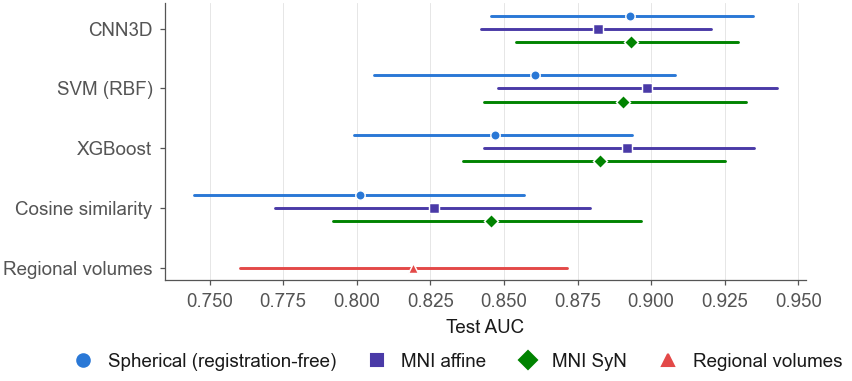

In [3]:
fig, ax = plt.subplots(figsize=(COL15, 2.4))
rows = CLASSIFIERS + ["Regional volumes"]
ys = np.arange(len(rows))[::-1]
offs = {"Spherical": 0.22, "MNI affine": 0.0, "MNI SyN": -0.22}
for y, clf in zip(ys, rows):
    reps = ["MNI SyN"] if clf == "Regional volumes" else REPS
    for rep in reps:
        c = ROI if clf == "Regional volumes" else config(clf, rep)
        r = summary.loc[c]
        dy = 0.0 if clf == "Regional volumes" else offs[rep]
        col = REP_COLOR["Regional volumes" if clf == "Regional volumes" else rep]
        ax.plot([r["AUC_lo"], r["AUC_hi"]], [y + dy, y + dy], color=col, lw=1.4, solid_capstyle="round")
        ax.plot(r["AUC_mean"], y + dy, REP_MARKER["Regional volumes" if clf == "Regional volumes" else rep],
                ms=4.5, color=col, mec="white", mew=0.7, zorder=5)
ax.set_yticks(ys, ["CNN3D", "SVM (RBF)", "XGBoost", "Cosine similarity", "Regional volumes"])
ax.set_xlabel("Test AUC")
ax.grid(axis="y", visible=False)
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], marker=REP_MARKER[r], ls="", color=REP_COLOR[r], label=r + (" (registration-free)" if r == "Spherical" else ""))
                   for r in REPS + ["Regional volumes"]],
          loc="upper center", bbox_to_anchor=(0.45, -0.2), ncol=4, handletextpad=0.3, columnspacing=1.2)
save(fig, "fig9_registration_grid",
     "Test AUC of every classifier on every representation of the same subjects: the registration-free "
     "spherical tensor, MNI-registered volumes (ANTs affine, ANTs SyN; MNI152 2009, 2 mm) and atlas regional "
     "volumes. Dots: mean over seeds (CNN3D and XGBoost: 5 seeds); bars: 95% bootstrap CI of the seed-mean.")
plt.show()

## 2. Pre-specified comparisons (own Holm family)

**fig10_registration_pairs** (140 × 61 mm): Pre-specified comparisons between the registration-free spherical representation and registration-based processing of the same subjects. ΔAUC > 0 favours registration-free. Bars: 95% paired-bootstrap CI; labels: Holm-adjusted p-values within this family of five comparisons (bold, black: p < 0.05).

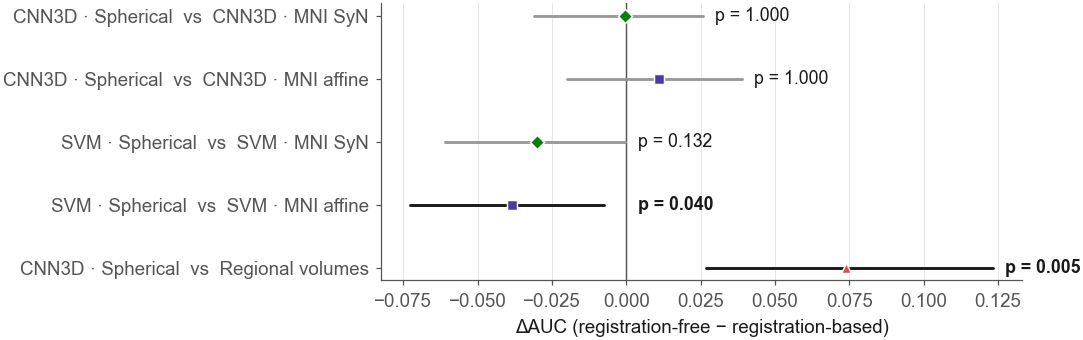

,Comparison,ΔAUC,95% CI,p (Holm)
0,CNN3D · Spherical vs CNN3D · MNI SyN,-0.000,-0.031 to +0.026,1.000
1,CNN3D · Spherical vs CNN3D · MNI affine,+0.011,-0.020 to +0.039,1.000
2,SVM · Spherical vs SVM · MNI SyN,-0.030,-0.061 to -0.001,0.132
3,SVM · Spherical vs SVM · MNI affine,-0.038,-0.073 to -0.007,0.040
4,CNN3D · Spherical vs Regional volumes,+0.074,+0.027 to +0.123,0.005


- CNN3D · Spherical vs CNN3D · MNI SyN: ΔAUC -0.000 (95% CI -0.031 to +0.026, Holm p = 1.000): **no significant difference**.
- CNN3D · Spherical vs CNN3D · MNI affine: ΔAUC +0.011 (95% CI -0.020 to +0.039, Holm p = 1.000): **no significant difference**.
- SVM · Spherical vs SVM · MNI SyN: ΔAUC -0.030 (95% CI -0.061 to -0.001, Holm p = 0.132): **no significant difference**.
- SVM · Spherical vs SVM · MNI affine: ΔAUC -0.038 (95% CI -0.073 to -0.007, Holm p = 0.040): **registration-based better**.
- CNN3D · Spherical vs Regional volumes: ΔAUC +0.074 (95% CI +0.027 to +0.123, Holm p = 0.005): **registration-free better**.

In [4]:
fig, ax = plt.subplots(figsize=(COL15, 0.36 * len(regcomp) + 0.6))
ys = np.arange(len(regcomp))[::-1]
ax.axvline(0, color=INK_2, lw=0.7)
for y, (_, r) in zip(ys, regcomp.iterrows()):
    strong = r["p_holm"] < 0.05
    col = REP_COLOR[rep_of(r["config_b"])]
    ax.plot([r["lo"], r["hi"]], [y, y], color=INK if strong else "#9a9a9a", lw=1.4, solid_capstyle="round")
    ax.plot(r["delta_AUC"], y, REP_MARKER[rep_of(r["config_b"])], ms=4.5, color=col, mec="white", mew=0.7, zorder=5)
    ax.text(max(r["hi"], 0) + 0.004, y, pfmt(r["p_holm"]), va="center", fontsize=8.5, fontweight="bold" if strong else "normal")
ax.set_yticks(ys, [f"{label(a)}  vs  {label(b)}" for a, b in zip(regcomp["config_a"], regcomp["config_b"])])
ax.set_xlabel("ΔAUC (registration-free − registration-based)")
ax.grid(axis="y", visible=False)
save(fig, "fig10_registration_pairs",
     "Pre-specified comparisons between the registration-free spherical representation and registration-based "
     "processing of the same subjects. ΔAUC > 0 favours registration-free. Bars: 95% paired-bootstrap CI; "
     "labels: Holm-adjusted p-values within this family of five comparisons (bold, black: p < 0.05).")
plt.show()

def verdict(r):
    if r.p_holm >= 0.05:
        return "**no significant difference**"
    return "**registration-free better**" if r.delta_AUC > 0 else "**registration-based better**"
t = regcomp.assign(**{"Comparison": [f"{label(a)} vs {label(b)}" for a, b in zip(regcomp.config_a, regcomp.config_b)],
                      "ΔAUC": regcomp.delta_AUC.map("{:+.3f}".format),
                      "95% CI": [f"{l:+.3f} to {h:+.3f}" for l, h in zip(regcomp.lo, regcomp.hi)],
                      "p (Holm)": regcomp.p_holm.map(lambda p: "<0.001" if p < 0.001 else f"{p:.3f}")})[["Comparison", "ΔAUC", "95% CI", "p (Holm)"]]
display(t)
display(Markdown("\n".join(f"- {label(r.config_a)} vs {label(r.config_b)}: ΔAUC {r.delta_AUC:+.3f} "
                           f"(95% CI {r.lo:+.3f} to {r.hi:+.3f}, Holm {pfmt(r.p_holm)}): {verdict(r)}."
                           for r in regcomp.itertuples())))

## 2b. Does registering first improve the spherical representation?

The **same spherical transform and the same models** (CNN3D *and* Spherical Transformer), applied to
the native brain (registration-free) versus the SyN-registered brain. Because every registered brain
shares the template's mask, its centre and boundary are identical across subjects; only the
intensities differ. Pre-specified, own Holm family of two comparisons
(ΔAUC = native − registered).

,Model,AUC native (registration-free),AUC registered first (SyN),ΔAUC (native − registered),95% CI,p (Holm)
0,CNN3D,0.893 ± 0.007,0.909 ± 0.012,-0.016,-0.034 to +0.000,0.116
1,Spherical Transformer,0.882 ± 0.012,0.876 ± 0.009,+0.007,-0.016 to +0.032,0.602


- CNN3D: AUC 0.893 native vs 0.909 registered first; ΔAUC -0.016 (95% CI -0.034 to +0.000, Holm p = 0.116): **no significant difference**.
- Spherical Transformer: AUC 0.882 native vs 0.876 registered first; ΔAUC +0.007 (95% CI -0.016 to +0.032, Holm p = 0.602): **no significant difference**.

Within-protocol test AUC:

,≤1.0 mm voxels,1.2 mm slices
CNN3D · Spherical,0.897,0.868
CNN3D · Spherical of MNI SyN,0.925,0.876
Spherical Transformer · Spherical,0.860,0.858
Spherical Transformer · Spherical of MNI SyN,0.836,0.843


**fig13_registration_spherical** (140 × 38 mm): Spherical representation of the native brain (registration-free) versus of the SyN-registered brain, for CNN3D and the Spherical Transformer (same transform, models, training and thresholds). Dots: mean over five seeds; bars: 95% bootstrap CI; labels: ΔAUC (native − registered) with Holm-adjusted p (family of two).

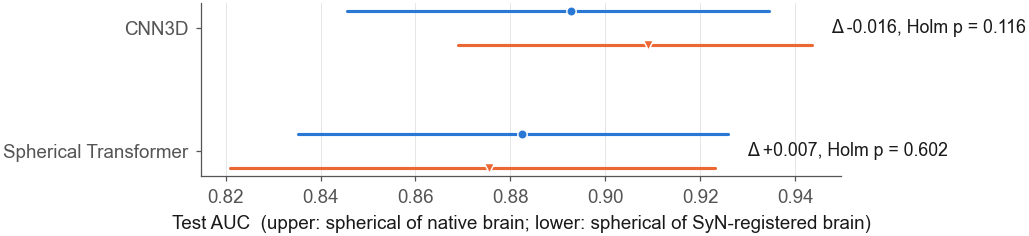

In [5]:
rs_path = RESULTS_DIR / "registration_spherical_comparison.csv"
if not rs_path.exists():
    display(Markdown("`registration_spherical_comparison.csv` not found yet -- run the `-RegisteredSpherical` "
                     "training (`RESUME_TRAINING.bat`) and `evaluate.py`."))
else:
    rsc = pd.read_csv(rs_path)
    tab = pd.DataFrame({
        "Model": [label(a).split(" · ")[0] for a in rsc.config_a],
        "AUC native (registration-free)": [f"{summary.loc[a,'AUC_mean']:.3f} ± {summary.loc[a,'AUC_sd']:.3f}" for a in rsc.config_a],
        "AUC registered first (SyN)": [f"{summary.loc[b,'AUC_mean']:.3f} ± {summary.loc[b,'AUC_sd']:.3f}" for b in rsc.config_b],
        "ΔAUC (native − registered)": rsc.delta_AUC.map("{:+.3f}".format),
        "95% CI": [f"{l:+.3f} to {h:+.3f}" for l, h in zip(rsc.lo, rsc.hi)],
        "p (Holm)": rsc.p_holm.map(lambda p: "<0.001" if p < 0.001 else f"{p:.3f}")})
    display(tab)
    display(Markdown("\n".join(
        f"- {label(r.config_a).split(' · ')[0]}: AUC {summary.loc[r.config_a,'AUC_mean']:.3f} native vs "
        f"{summary.loc[r.config_b,'AUC_mean']:.3f} registered first; ΔAUC {r.delta_AUC:+.3f} "
        f"(95% CI {r.lo:+.3f} to {r.hi:+.3f}, Holm {pfmt(r.p_holm)}): {verdict(r)}."
        for r in rsc.itertuples())))
    (FIG_DIR / "table6_registration_spherical.tex").write_text(
        tab.rename(columns={"ΔAUC (native − registered)": r"$\Delta$AUC (native $-$ registered)", "95% CI": r"95\% CI"})
           .to_latex(index=False, escape=False).replace("±", r"$\pm$").replace("<0.001", "$<$0.001"), encoding="utf-8")

    sgp = subgroup[subgroup.config.isin(list(rsc.config_a) + list(rsc.config_b))].pivot(index="config", columns="protocol", values="AUC_mean")
    sgp.index = [label(c) for c in sgp.index]; sgp.columns = [PROTO[p] for p in sgp.columns]
    display(Markdown("Within-protocol test AUC:")); display(sgp.round(3))

    fig, ax = plt.subplots(figsize=(COL15, 1.5))
    ys = np.arange(len(rsc))[::-1]
    for y, r in zip(ys, rsc.itertuples()):
        for cfg, dy in ((r.config_a, 0.14), (r.config_b, -0.14)):
            s_ = summary.loc[cfg]; rep = rep_of(cfg)
            ax.plot([s_["AUC_lo"], s_["AUC_hi"]], [y + dy] * 2, color=REP_COLOR[rep], lw=1.5, solid_capstyle="round")
            ax.plot(s_["AUC_mean"], y + dy, REP_MARKER[rep], ms=4.5, color=REP_COLOR[rep], mec="white", mew=0.7, zorder=5)
        ax.text(max(summary.loc[r.config_a, "AUC_hi"], summary.loc[r.config_b, "AUC_hi"]) + 0.004, y,
                f"Δ {r.delta_AUC:+.3f}, Holm {pfmt(r.p_holm)}", va="center", fontsize=8.5, fontweight="bold" if r.p_holm < 0.05 else "normal")
    ax.set_yticks(ys, [label(a).split(" · ")[0] for a in rsc.config_a])
    ax.set_xlabel("Test AUC  (upper: spherical of native brain; lower: spherical of SyN-registered brain)")
    ax.grid(axis="y", visible=False)
    save(fig, "fig13_registration_spherical",
         "Spherical representation of the native brain (registration-free) versus of the SyN-registered brain, "
         "for CNN3D and the Spherical Transformer (same transform, models, training and thresholds). Dots: mean over "
         "five seeds; bars: 95% bootstrap CI; labels: ΔAUC (native − registered) with Holm-adjusted p (family of two).")
    plt.show()

## 3. ROC curves of the main contenders

**fig11_registration_roc** (90 × 117 mm): Test ROC curves of CNN3D on the registration-free spherical tensor and on MNI-registered volumes (affine, SyN), of the best registration-based classical model (SVM on affine-registered voxels) and of the atlas regional-volume classifier. CNN3D curves: vertical average over five seeds, band ±1 SD.

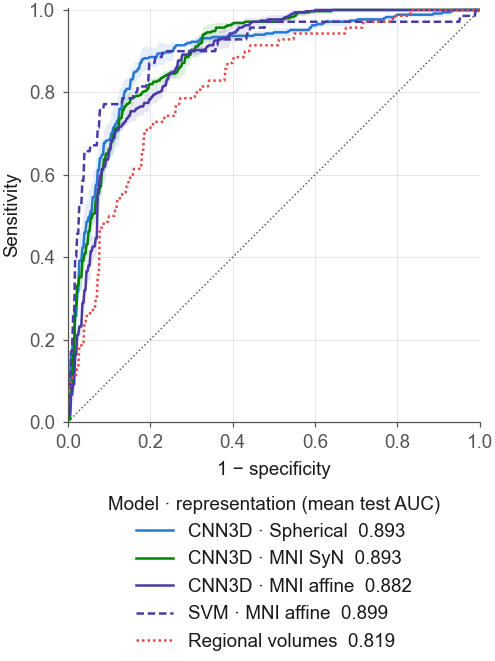

In [6]:
grid_x = np.linspace(0, 1, 401)
def roc_points(y, s):
    o = np.argsort(-s, kind="mergesort"); y, s = y[o], s[o]
    d = np.r_[np.flatnonzero(np.diff(s)), len(s) - 1]
    tps = np.cumsum(y)[d]; fps = (d + 1) - tps
    return np.r_[0, fps / fps[-1]], np.r_[0, tps / tps[-1]]

test = preds[preds["split"] == "test"]
show = ["CNN3D (best epoch)", "CNN3D, MNI SyN (best epoch)", "CNN3D, MNI affine (best epoch)",
        "SVM (RBF), MNI affine", ROI]
styles = {"CNN3D (best epoch)": "-", "CNN3D, MNI SyN (best epoch)": "-", "CNN3D, MNI affine (best epoch)": "-",
          "SVM (RBF), MNI affine": (0, (3, 1.5)), ROI: (0, (1, 1.2))}
fig, ax = plt.subplots(figsize=(COL1, COL1 * 1.3))
ax.plot([0, 1], [0, 1], ls=":", lw=0.7, color=INK_2)
for c in show:
    curves = []
    for _, g in test[test["config"] == c].groupby("seed", dropna=False):
        f, tp = roc_points(g["label"].to_numpy(), g["score"].to_numpy())
        curves.append(np.interp(grid_x, f, tp))
    curves = np.array(curves); m = curves.mean(0)
    ax.plot(grid_x, m, color=REP_COLOR[rep_of(c)], ls=styles[c], lw=1.2, label=f"{label(c)}  {summary.loc[c, 'AUC_mean']:.3f}")
    if len(curves) > 1:
        sd = curves.std(0); ax.fill_between(grid_x, np.clip(m - sd, 0, 1), np.clip(m + sd, 0, 1), color=REP_COLOR[rep_of(c)], alpha=0.12, lw=0)
ax.set(xlabel="1 − specificity", ylabel="Sensitivity", xlim=(0, 1), ylim=(0, 1.005), aspect="equal")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), title="Model · representation (mean test AUC)", borderaxespad=0)
save(fig, "fig11_registration_roc",
     "Test ROC curves of CNN3D on the registration-free spherical tensor and on MNI-registered volumes (affine, SyN), "
     "of the best registration-based classical model (SVM on affine-registered voxels) and of the atlas regional-volume "
     "classifier. CNN3D curves: vertical average over five seeds, band ±1 SD.")
plt.show()

## 4. Robustness across acquisition protocols

Within-protocol test AUC (from `evaluate.py`). The 1.2 mm-slice scans are mostly the first ADNI phase
(1.5 T); the ≤1.0 mm scans are mostly later phases (3 T). Note that the ≤1.0 mm test subgroup has only
12 Dementia cases, so its intervals are wide.

**fig12_registration_protocol** (190 × 61 mm): Test AUC within each acquisition protocol for every classifier on the registration-free spherical tensor and on MNI-registered volumes: (a) 1.2 mm-slice scans, (b) ≤1.0 mm scans. Bars: 95% bootstrap CI (resampling within the protocol).

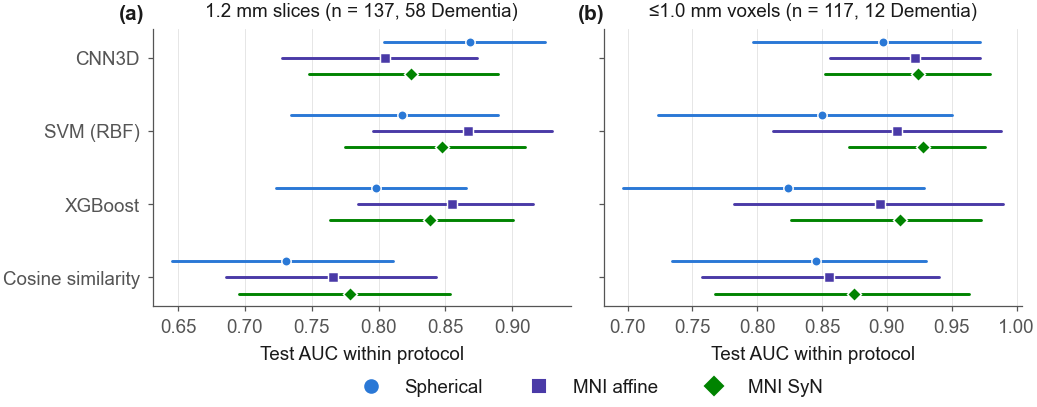

,Overall,≤1.0 mm voxels,1.2 mm slices,Gap (≤1.0 − 1.2)
CNN3D · Spherical,0.893,0.897,0.868,0.028
CNN3D · MNI affine,0.882,0.921,0.805,0.116
CNN3D · MNI SyN,0.893,0.924,0.824,0.100
SVM · Spherical,0.860,0.850,0.818,0.032
SVM · MNI affine,0.899,0.908,0.867,0.041
SVM · MNI SyN,0.891,0.928,0.848,0.080
XGBoost · Spherical,0.847,0.824,0.798,0.026
XGBoost · MNI affine,0.892,0.894,0.855,0.039
XGBoost · MNI SyN,0.883,0.910,0.839,0.071
Cosine Similarity · Spherical,0.801,0.845,0.730,0.115


In [7]:
protos = ["slice1.2", "iso1.0"]
fig, axes = plt.subplots(1, 2, figsize=(COL2, 2.4), sharey=True, gridspec_kw={"wspace": 0.08})
rows = CLASSIFIERS
ys = np.arange(len(rows))[::-1]
offs = {"Spherical": 0.22, "MNI affine": 0.0, "MNI SyN": -0.22}
for i, (ax, proto) in enumerate(zip(axes, protos)):
    sg = subgroup[subgroup["protocol"] == proto].set_index("config")
    for y, clf in zip(ys, rows):
        for rep in REPS:
            r = sg.loc[config(clf, rep)]
            ax.plot([r["AUC_lo"], r["AUC_hi"]], [y + offs[rep]] * 2, color=REP_COLOR[rep], lw=1.4, solid_capstyle="round")
            ax.plot(r["AUC_mean"], y + offs[rep], REP_MARKER[rep], ms=4.5, color=REP_COLOR[rep], mec="white", mew=0.7, zorder=5)
    first = sg.iloc[0]
    ax.set_title(f"{PROTO[proto]} (n = {int(first['n'])}, {int(first['n_dementia'])} Dementia)")
    ax.set_xlabel("Test AUC within protocol"); ax.grid(axis="y", visible=False)
    panel(ax, "ab"[i], x=0.0 if i else -0.02)
axes[0].set_yticks(ys, ["CNN3D", "SVM (RBF)", "XGBoost", "Cosine similarity"])
from matplotlib.lines import Line2D
axes[1].legend(handles=[Line2D([], [], marker=REP_MARKER[r], ls="", color=REP_COLOR[r], label=r) for r in REPS],
               loc="upper center", bbox_to_anchor=(-0.04, -0.2), ncol=3)
save(fig, "fig12_registration_protocol",
     "Test AUC within each acquisition protocol for every classifier on the registration-free spherical tensor "
     "and on MNI-registered volumes: (a) 1.2 mm-slice scans, (b) ≤1.0 mm scans. Bars: 95% bootstrap CI "
     "(resampling within the protocol).")
plt.show()

piv = subgroup[subgroup.config.isin(needed)].pivot(index="config", columns="protocol", values="AUC_mean").loc[[c for c in needed if c in summary.index]]
piv.index = [label(c) for c in piv.index]; piv.columns = [PROTO[p] for p in piv.columns]
piv.insert(0, "Overall", [summary.loc[c, "AUC_mean"] for c in needed if c in summary.index])
piv["Gap (≤1.0 − 1.2)"] = piv[PROTO["iso1.0"]] - piv[PROTO["slice1.2"]]
display(piv.round(3))

### 4b. Exploratory: is the spherical CNN3D more robust on 1.2 mm-slice scans?

*Not pre-specified.* Paired bootstrap of the seed-mean AUC difference, **within each protocol**,
between CNN3D on the spherical tensor and CNN3D on each registered input (2,000 resamples of that
protocol's test subjects; no multiplicity correction; interpret as hypothesis-generating).

In [8]:
def seed_matrix(c, ptids):
    # (n_seeds, n_subjects) scores aligned to ptids, plus labels
    g = test[test["config"] == c]
    mats = [s.set_index("PTID").loc[ptids, "score"].to_numpy() for _, s in g.groupby("seed", dropna=False)]
    y = g.drop_duplicates("PTID").set_index("PTID").loc[ptids, "label"].to_numpy()
    return np.array(mats), y

rows = []
for proto in protos:
    ptids = manifest[(manifest.split == "test") & (manifest.protocol == proto)]["PTID"].tolist()
    A, y = seed_matrix("CNN3D (best epoch)", ptids)
    idx = bootstrap_indices(y, seed=45)
    bootA = np.mean([bootstrap_auc(y, a, idx) for a in A], axis=0)
    for rep in ("MNI SyN", "MNI affine"):
        B, _ = seed_matrix(config("CNN3D", rep), ptids)
        bootB = np.mean([bootstrap_auc(y, b, idx) for b in B], axis=0)
        d = bootA - bootB; lo, hi = percentile_ci(d)
        point = np.mean([_manual_auc(y, a) for a in A]) - np.mean([_manual_auc(y, b) for b in B])
        p = min(1.0, 2 * min((d <= 0).mean(), (d >= 0).mean()))
        rows.append({"Protocol": PROTO[proto], "n": len(y), "Dementia": int(y.sum()),
                     "Comparison": f"CNN3D · Spherical − CNN3D · {rep}", "ΔAUC": point, "lo": lo, "hi": hi,
                     "p (unadjusted)": max(p, 1 / len(d))})
expl = pd.DataFrame(rows)
display(expl.round(3))
display(Markdown("\n".join(
    f"- {r['Protocol']} (n = {r['n']}, {r['Dementia']} Dementia), {r['Comparison']}: ΔAUC {r['ΔAUC']:+.3f} "
    f"(95% CI {r['lo']:+.3f} to {r['hi']:+.3f}; unadjusted {pfmt(r['p (unadjusted)'])})." for _, r in expl.iterrows())))

,Protocol,n,Dementia,Comparison,ΔAUC,lo,hi,p (unadjusted)
0,1.2 mm slices,137,58,CNN3D · Spherical − CNN3D · MNI SyN,0.045,0.010,0.079,0.016
1,1.2 mm slices,137,58,CNN3D · Spherical − CNN3D · MNI affine,0.063,0.026,0.102,0.002
2,≤1.0 mm voxels,117,12,CNN3D · Spherical − CNN3D · MNI SyN,-0.027,-0.076,0.018,0.235
3,≤1.0 mm voxels,117,12,CNN3D · Spherical − CNN3D · MNI affine,-0.025,-0.083,0.026,0.363


- 1.2 mm slices (n = 137, 58 Dementia), CNN3D · Spherical − CNN3D · MNI SyN: ΔAUC +0.045 (95% CI +0.010 to +0.079; unadjusted p = 0.016).
- 1.2 mm slices (n = 137, 58 Dementia), CNN3D · Spherical − CNN3D · MNI affine: ΔAUC +0.063 (95% CI +0.026 to +0.102; unadjusted p = 0.002).
- ≤1.0 mm voxels (n = 117, 12 Dementia), CNN3D · Spherical − CNN3D · MNI SyN: ΔAUC -0.027 (95% CI -0.076 to +0.018; unadjusted p = 0.235).
- ≤1.0 mm voxels (n = 117, 12 Dementia), CNN3D · Spherical − CNN3D · MNI affine: ΔAUC -0.025 (95% CI -0.083 to +0.026; unadjusted p = 0.363).

## 5. Exploratory: do the spherical and registered CNNs see the same thing?

*Not pre-specified.* If two models of equal AUC rank subjects differently, their information is partly
complementary. Per-subject scores are averaged over the five seeds of each model; the combination is
the mean of the two rank-normalized scores (no fitting on test data).

,Pair,Spearman ρ of scores,AUC spherical (seed-avg score),AUC registered (seed-avg score),AUC combined,Δ combined − spherical,95% CI
0,Spherical + MNI SyN,0.896,0.896,0.895,0.904,0.007,-0.007 to +0.022
1,Spherical + MNI affine,0.883,0.896,0.882,0.898,0.002,-0.014 to +0.017


**figS4_registration_agreement** (140 × 61 mm): Per-subject agreement between CNN3D on the registration-free spherical tensor and on MNI-registered volumes (test partition; scores averaged over five seeds and shown as percentiles): (a) SyN, (b) affine. Points far from the diagonal are ranked differently by the two representations.

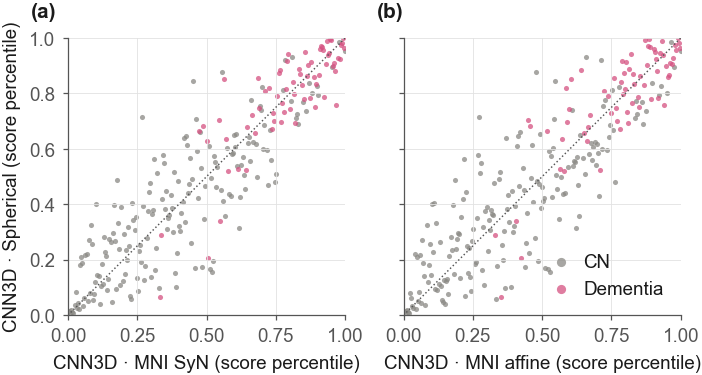

In [9]:
def mean_score(c):
    g = test[test["config"] == c]
    return g.groupby("PTID")["score"].mean(), g.drop_duplicates("PTID").set_index("PTID")["label"]

sph, y_all = mean_score("CNN3D (best epoch)")
rows, combos = [], {}
for rep in ("MNI SyN", "MNI affine"):
    reg, _ = mean_score(config("CNN3D", rep))
    reg = reg.loc[sph.index]
    y = y_all.loc[sph.index].to_numpy()
    rs, rr = sph.rank(pct=True).to_numpy(), reg.rank(pct=True).to_numpy()
    comb = (rs + rr) / 2
    idx = bootstrap_indices(y, seed=46)
    bs, bc = bootstrap_auc(y, rs, idx), bootstrap_auc(y, comb, idx)
    lo, hi = percentile_ci(bc - bs)
    rows.append({"Pair": f"Spherical + {rep}", "Spearman ρ of scores": pd.Series(rs).corr(pd.Series(rr), method="spearman"),
                 "AUC spherical (seed-avg score)": _manual_auc(y, rs), "AUC registered (seed-avg score)": _manual_auc(y, rr),
                 "AUC combined": _manual_auc(y, comb), "Δ combined − spherical": _manual_auc(y, comb) - _manual_auc(y, rs),
                 "95% CI": f"{lo:+.3f} to {hi:+.3f}"})
    combos[rep] = (rs, rr, y)
display(pd.DataFrame(rows).round(3))

fig, axes = plt.subplots(1, 2, figsize=(COL15, 2.4), sharey=True, gridspec_kw={"wspace": 0.1})
for i, (ax, rep) in enumerate(zip(axes, ("MNI SyN", "MNI affine"))):
    rs, rr, y = combos[rep]
    for lab, col, name in ((0, "#8a8984", "CN"), (1, "#d55181", "Dementia")):
        k = y == lab
        ax.scatter(rr[k], rs[k], s=6, color=col, alpha=0.75, linewidths=0, label=name)
    ax.plot([0, 1], [0, 1], ls=":", lw=0.7, color=INK_2)
    ax.set(xlim=(0, 1), ylim=(0, 1), aspect="equal", xlabel=f"CNN3D · {rep} (score percentile)")
    panel(ax, "ab"[i], x=0.0 if i else -0.04, y=1.06)
axes[0].set_ylabel("CNN3D · Spherical (score percentile)")
axes[1].legend(loc="lower right", markerscale=1.8, handletextpad=0.2)
save(fig, "figS4_registration_agreement",
     "Per-subject agreement between CNN3D on the registration-free spherical tensor and on MNI-registered volumes "
     "(test partition; scores averaged over five seeds and shown as percentiles): (a) SyN, (b) affine. "
     "Points far from the diagonal are ranked differently by the two representations.")
plt.show()

## 6. Registration quality and processing cost

In [10]:
if qc is not None:
    q = qc.merge(manifest[["PTID"]], on="PTID")
    display(Markdown(
        f"Registration quality (correlation of each warped brain with the template inside the template brain mask): "
        f"affine median **{q.affine.median():.3f}**, SyN median **{q.syn.median():.3f}**; SyN improved on affine for "
        f"**{(q.syn > q.affine).mean():.0%}** of subjects. Visual review of the lowest-correlation subjects showed correct "
        f"registrations of strongly atrophied brains (enlarged ventricles), not failures; no subject was excluded. "
        f"Median SyN correlation: CN {q[q.Diagnosis == 'CN'].syn.median():.3f} vs Dementia {q[q.Diagnosis == 'Dementia'].syn.median():.3f}."))
display(Markdown(r'''
**Processing cost per subject (this machine, measured during the study):**

| Step | Spherical (registration-free) | MNI affine | MNI SyN |
|---|---|---|---|
| N4 + resampling / transform | ≈ 8 s | (N4 shared) | (N4 shared) |
| ANTs registration, all cores | – | ≈ 1.2 s | ≈ 2.4 s |
| ANTs registration, 1 thread (deterministic) | – | – | ≈ 30 s (affine + SyN + atlas) |

At 2 mm template resolution, registration is **not** a computational bottleneck, so the case for the
registration-free representation must rest on accuracy, robustness and independence from a template —
not on speed.'''))

Registration quality (correlation of each warped brain with the template inside the template brain mask): affine median **0.525**, SyN median **0.675**; SyN improved on affine for **100%** of subjects. Visual review of the lowest-correlation subjects showed correct registrations of strongly atrophied brains (enlarged ventricles), not failures; no subject was excluded. Median SyN correlation: CN 0.679 vs Dementia 0.654.


**Processing cost per subject (this machine, measured during the study):**

| Step | Spherical (registration-free) | MNI affine | MNI SyN |
|---|---|---|---|
| N4 + resampling / transform | ≈ 8 s | (N4 shared) | (N4 shared) |
| ANTs registration, all cores | – | ≈ 1.2 s | ≈ 2.4 s |
| ANTs registration, 1 thread (deterministic) | – | – | ≈ 30 s (affine + SyN + atlas) |

At 2 mm template resolution, registration is **not** a computational bottleneck, so the case for the
registration-free representation must rest on accuracy, robustness and independence from a template —
not on speed.

## 7. Summary

In [11]:
cnn = regcomp[regcomp.config_a.eq("CNN3D (best epoch)") & regcomp.config_b.str.contains("CNN3D, MNI")]
svm = regcomp[regcomp.config_a.eq("SVM (RBF)")]
roi = regcomp[regcomp.config_b.eq(ROI)]
best_reg = summary.loc[[c for c in needed if c != ROI and rep_of(c) != "Spherical"], "AUC_mean"].idxmax()
lines = [
    f"1. **Deep model: registration-free matches registration.** CNN3D reaches AUC {summary.loc['CNN3D (best epoch)','AUC_mean']:.3f} on the spherical tensor vs "
    + " and ".join(f"{summary.loc[r.config_b,'AUC_mean']:.3f} on {rep_of(r.config_b)} (Δ {r.delta_AUC:+.3f}, Holm {pfmt(r.p_holm)})" for r in cnn.itertuples()) + ".",
    f"2. **Classical models benefit from registration.** SVM: " + "; ".join(
        f"{summary.loc[r.config_b,'AUC_mean']:.3f} on {rep_of(r.config_b)} vs {summary.loc['SVM (RBF)','AUC_mean']:.3f} spherical (Δ {r.delta_AUC:+.3f}, Holm {pfmt(r.p_holm)})"
        for r in svm.itertuples()) + f". The highest registration-based AUC is {label(best_reg)} ({summary.loc[best_reg,'AUC_mean']:.3f}).",
    f"3. **The spherical CNN3D beats the atlas regional-volume classifier:** Δ {roi.delta_AUC.iloc[0]:+.3f} (Holm {pfmt(roi.p_holm.iloc[0])}).",
    "4. **Protocol robustness (exploratory, not pre-specified):** " + "; ".join(
        f"{r['Protocol']}: spherical − {r['Comparison'].split('· ')[-1]} ΔAUC {r['ΔAUC']:+.3f} (95% CI {r['lo']:+.3f} to {r['hi']:+.3f})"
        for _, r in expl.iterrows()) + ". The registration-free CNN is more robust on the 1.2 mm-slice scans; on ≤1.0 mm scans "
        "the registered CNNs are slightly, not significantly, better (12 Dementia cases).",
    "5. **Complementarity (exploratory):** the two CNNs rank subjects similarly (Spearman ρ ≈ "
        f"{pd.DataFrame(rows)['Spearman ρ of scores'].mean():.2f}); combining them adds little "
        f"(Δ AUC {pd.DataFrame(rows)['Δ combined − spherical'].max():+.3f} at most, CI including 0).",
]
rs_path = RESULTS_DIR / "registration_spherical_comparison.csv"
if rs_path.exists():
    rsc = pd.read_csv(rs_path)
    lines.append("6. **Registering before the spherical transform (pre-specified, own Holm family of two):** " + "; ".join(
        f"{label(r.config_a).split(' · ')[0]} {summary.loc[r.config_a,'AUC_mean']:.3f} native vs "
        f"{summary.loc[r.config_b,'AUC_mean']:.3f} registered first (Δ {r.delta_AUC:+.3f}, 95% CI {r.lo:+.3f} to {r.hi:+.3f}, "
        f"Holm {pfmt(r.p_holm)})" for r in rsc.itertuples())
        + ". " + ("Neither difference is significant." if (rsc.p_holm >= 0.05).all() else "See Section 2b."))
display(Markdown("\n".join(lines)))
order = ["fig9_registration_grid", "fig10_registration_pairs", "fig13_registration_spherical", "fig11_registration_roc", "fig12_registration_protocol", "figS4_registration_agreement"]
(FIG_DIR / "captions_registration.md").write_text(
    "# Draft captions: registration comparison\n\n" + "\n\n".join(f"**{n}.** {CAPTIONS[n]}" for n in order if n in CAPTIONS) + "\n",
    encoding="utf-8")
print("captions written:", FIG_DIR / "captions_registration.md")

1. **Deep model: registration-free matches registration.** CNN3D reaches AUC 0.893 on the spherical tensor vs 0.893 on MNI SyN (Δ -0.000, Holm p = 1.000) and 0.882 on MNI affine (Δ +0.011, Holm p = 1.000).
2. **Classical models benefit from registration.** SVM: 0.891 on MNI SyN vs 0.860 spherical (Δ -0.030, Holm p = 0.132); 0.899 on MNI affine vs 0.860 spherical (Δ -0.038, Holm p = 0.040). The highest registration-based AUC is SVM · MNI affine (0.899).
3. **The spherical CNN3D beats the atlas regional-volume classifier:** Δ +0.074 (Holm p = 0.005).
4. **Protocol robustness (exploratory, not pre-specified):** 1.2 mm slices: spherical − MNI SyN ΔAUC +0.045 (95% CI +0.010 to +0.079); 1.2 mm slices: spherical − MNI affine ΔAUC +0.063 (95% CI +0.026 to +0.102); ≤1.0 mm voxels: spherical − MNI SyN ΔAUC -0.027 (95% CI -0.076 to +0.018); ≤1.0 mm voxels: spherical − MNI affine ΔAUC -0.025 (95% CI -0.083 to +0.026). The registration-free CNN is more robust on the 1.2 mm-slice scans; on ≤1.0 mm scans the registered CNNs are slightly, not significantly, better (12 Dementia cases).
5. **Complementarity (exploratory):** the two CNNs rank subjects similarly (Spearman ρ ≈ 0.89); combining them adds little (Δ AUC +0.007 at most, CI including 0).
6. **Registering before the spherical transform (pre-specified, own Holm family of two):** CNN3D 0.893 native vs 0.909 registered first (Δ -0.016, 95% CI -0.034 to +0.000, Holm p = 0.116); Spherical Transformer 0.882 native vs 0.876 registered first (Δ +0.007, 95% CI -0.016 to +0.032, Holm p = 0.602). Neither difference is significant.

captions written: F:\adni-spherical-classification\figures\captions_registration.md
